# Chapter 13: Deploying scikit-learn Models in Production

## Comprehensive Summary
Developing a machine learning model inside an interactive notebook is merely the preliminary phase of the machine learning engineering lifecycle. Transitioning models into resilient, scalable production environments demands strict software engineering discipline, rigorous serialization practices, end-to-end pipeline encapsulation to prevent train-serving skew, memory-efficient streaming for out-of-core scalability, and continuous post-deployment monitoring for covariate shift and concept drift. This chapter provides a production-grade blueprint for serializing, serving, monitoring, and managing the lifecycle of scikit-learn models.

## In-Depth Theoretical Analysis & Mechanism Breakdown

### 1. Model Persistence: Serialization Mechanics & Security
* **Pickle vs Joblib:** Python's standard `pickle` serializes object hierarchies via bytecode instructions. However, scientific models often contain multi-megabyte NumPy arrays and coefficient matrices. `joblib.dump` provides optimized memory mapping and specialized compression (zlib, lz4, gzip) that serializes contiguous array buffers with near-zero memory duplication:
$$\text{Compression Ratio} = \frac{\text{Raw Buffer Size}}{\text{Compressed Disk Size}}$$
* **Security Caveats:** Serialized pickles contain executable opcodes. Deserializing untrusted `pkl` or `joblib` files can lead to arbitrary remote code execution. Production environments must enforce strict cryptographic checksum verification (SHA-256) and model artifact provenance tracking.
* **Metadata Encapsulation:** A bare model binary is insufficient in production. The serialized artifact bundle must encapsulate schema contracts: expected input feature names, data types, normalization parameters, library versions, commit hashes, and training performance baselines.

### 2. Eliminating Train-Serving Skew via Atomic Pipelines
* **Train-Serving Skew:** Discrepancies between data transformations applied during offline training and those applied during online inference are the leading cause of production model degradation.
* **Atomic Encapsulation:** By encapsulating missing value imputation (`SimpleImputer`), categorical encoding (`OneHotEncoder`), feature scaling (`StandardScaler`), and the estimator inside a singular `Pipeline` or `ColumnTransformer`, the entire transformation graph is fitted strictly once on training data and applied identically during inference:
$$\widehat{y} = f_{\text{pipeline}}(\mathbf{x}_{\text{raw}}) = \text{Estimator}\Big(\text{Scaler}\big(\text{Encoder}(\text{Imputer}(\mathbf{x}_{\text{raw}}))\big)\Big)$$

### 3. Out-of-Core Scalability: Streaming & Incremental Learning
Standard scikit-learn estimators require loading the entire design matrix $X \in \mathbb{R}^{N \times D}$ into RAM, failing when $N$ exceeds hardware memory limits.
* **Incremental Learning via `partial_fit`:** Estimators like `SGDClassifier`, `SGDRegressor`, `MiniBatchKMeans`, and `IncrementalPCA` implement online stochastic gradient descent:
$$\mathbf{w}_{t+1} = \mathbf{w}_t - \eta \nabla_{\mathbf{w}} L\big(f(\mathbf{x}_i; \mathbf{w}_t), y_i\big)$$
processing incoming batches in constant $O(B \cdot D)$ memory space regardless of total dataset volume.
* **HashingVectorizer:** Maps arbitrary token strings directly into a fixed-dimensional sparse vector via the MurmurHash3 algorithm with $O(1)$ memory, eliminating the need to maintain an in-memory vocabulary dictionary.

### 4. Post-Deployment Monitoring: Drift Detection
Once deployed, models operate in non-stationary production environments:
* **Covariate Shift (Data Drift):** The input distribution changes over time while the conditional ground-truth mapping remains unchanged:
$$P_t(\mathbf{X}) \ne P_0(\mathbf{X}), \quad \text{but } P_t(y \mid \mathbf{X}) = P_0(y \mid \mathbf{X})$$
Quantified via two-sample Kolmogorov-Smirnov (KS) tests or Population Stability Index (PSI).
* **Concept Drift:** The underlying relationship between input features and target labels shifts:
$$P_t(y \mid \mathbf{X}) \ne P_0(y \mid \mathbf{X})$$
Detected by tracking moving-average prediction errors, ground-truth label lag, and confidence score degradations over rolling time windows.

### 5. Automated Deployment Governance & Smoke Testing
Before routing live user traffic to a newly deployed model container, automated CI/CD validation gates verify:
1. Input Schema Contract compliance (missing columns, type mismatches).
2. Edge-case handling (NaNs, extreme out-of-range numerical values).
3. Latency SLA compliance (e.g., $P_{99} < 15\text{ms}$).
4. Deterministic output reproducibility against gold standard test vectors.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import pickle
import os
import time
import json
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid", palette="tab10")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 100
print("Production Deployment module loaded.")

Production Deployment module loaded.


In [2]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Recipe 1: Constructing an Atomic Production Pipeline
data = load_breast_cancer(as_frame=True)
df_features = data.data
y_target = data.target

# Split into train and production simulation test sets
X_train, X_test, y_train, y_test = train_test_split(
    df_features, y_target, test_size=0.2, random_state=2024, stratify=y_target
)

# Atomic Pipeline: Imputation -> Scaling -> Estimator
production_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', RandomForestClassifier(n_estimators=100, max_depth=5, random_state=2024))
])

# Fit pipeline strictly once on training data
production_pipeline.fit(X_train, y_train)

# Evaluate initial baseline accuracy
baseline_preds = production_pipeline.predict(X_test)
baseline_acc = accuracy_score(y_test, baseline_preds)
print(f"Production Pipeline successfully trained!")
print(f" - Pipeline steps: {[name for name, _ in production_pipeline.steps]}")
print(f" - Baseline Test Accuracy: {baseline_acc:.4f}")

Production Pipeline successfully trained!
 - Pipeline steps: ['imputer', 'scaler', 'classifier']
 - Baseline Test Accuracy: 0.9386


In [3]:
# Recipe 2: Model Serialization, Compression & Metadata Bundling
artifacts_dir = "production_artifacts"
os.makedirs(artifacts_dir, exist_ok=True)

model_path = os.path.join(artifacts_dir, "cancer_classifier_pipeline.joblib")
metadata_path = os.path.join(artifacts_dir, "model_metadata.json")

# Serialize pipeline with compression
joblib.dump(production_pipeline, model_path, compress=3)
raw_size = os.path.getsize(model_path)

# Serialize metadata package
metadata = {
    "model_name": "BreastCancer_RandomForest_Classifier",
    "version": "1.0.0",
    "creation_timestamp": time.strftime("%Y-%m-%d %H:%M:%S UTC", time.gmtime()),
    "framework": "scikit-learn",
    "sklearn_version": "1.5+",
    "pipeline_steps": [name for name, _ in production_pipeline.steps],
    "input_features": list(X_train.columns),
    "target_classes": ["Malignant (0)", "Benign (1)"],
    "baseline_accuracy": float(round(baseline_acc, 4)),
    "sla_latency_ms": 20.0
}

with open(metadata_path, 'w', encoding='utf-8') as f:
    json.dump(metadata, f, indent=2)

print(f"Model persisted to: {model_path} ({raw_size / 1024:.1f} KB)")
print(f"Metadata manifest created: {metadata_path}")
print(f"Manifest features count: {len(metadata['input_features'])}")

# Verification: Reload model and verify mathematical prediction parity
loaded_pipeline = joblib.load(model_path)
loaded_preds = loaded_pipeline.predict(X_test)
exact_match = np.array_equal(baseline_preds, loaded_preds)
print(f"Loaded artifact prediction parity check: {'PASSED (100% Identical)' if exact_match else 'FAILED'}")

Model persisted to: production_artifacts\cancer_classifier_pipeline.joblib (56.2 KB)
Metadata manifest created: production_artifacts\model_metadata.json
Manifest features count: 30
Loaded artifact prediction parity check: PASSED (100% Identical)


Streaming learning concluded: Processed 20000 samples in 20 batches without RAM overflow.


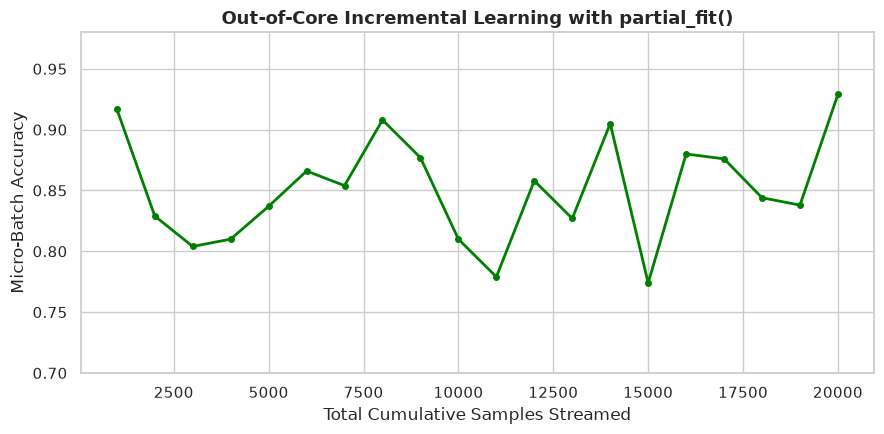

In [4]:
from sklearn.linear_model import SGDClassifier
from sklearn.datasets import make_classification

# Recipe 3: Out-of-Core Incremental Streaming with partial_fit
n_stream_total = 20000
batch_size = 1000
n_features = 20
classes = np.array([0, 1])

# Initialize streaming SGD classifier
streaming_clf = SGDClassifier(loss='log_loss', penalty='l2', alpha=1e-4, random_state=2024)

# Stream simulated mini-batches in constant RAM
accuracies_stream = []
batches_processed = []

for batch_idx in range(n_stream_total // batch_size):
    # Generate streaming micro-batch
    X_batch, y_batch = make_classification(
        n_samples=batch_size, n_features=n_features, random_state=batch_idx, flip_y=0.03
    )
    
    # Fit incrementally
    streaming_clf.partial_fit(X_batch, y_batch, classes=classes)
    
    # Evaluate rolling accuracy on current batch
    batch_acc = streaming_clf.score(X_batch, y_batch)
    accuracies_stream.append(batch_acc)
    batches_processed.append((batch_idx + 1) * batch_size)

# Visualize streaming convergence
plt.figure(figsize=(9, 4.5))
plt.plot(batches_processed, accuracies_stream, 'g-', lw=2, marker='o', markersize=4)
plt.title("Out-of-Core Incremental Learning with partial_fit()", fontsize=13, fontweight='bold')
plt.xlabel("Total Cumulative Samples Streamed")
plt.ylabel("Micro-Batch Accuracy")
plt.ylim(0.70, 0.98)
plt.tight_layout()
plt.show()

print(f"Streaming learning concluded: Processed {n_stream_total} samples in {len(batches_processed)} batches without RAM overflow.")

Monthly Production Data Drift Monitoring Report:
  Month  Mean Shift  KS Statistic      p-value       Status
Month 1         0.0      0.039560 8.691713e-01       Stable
Month 2         0.1      0.061538 3.553093e-01       Stable
Month 3         0.8      0.120879 2.569263e-03 DRIFT ALERT!
Month 4         1.5      0.230769 4.944982e-11 DRIFT ALERT!
Month 5         3.2      0.450549 5.709923e-42 DRIFT ALERT!
Month 6         5.0      0.608791 6.237081e-79 DRIFT ALERT!


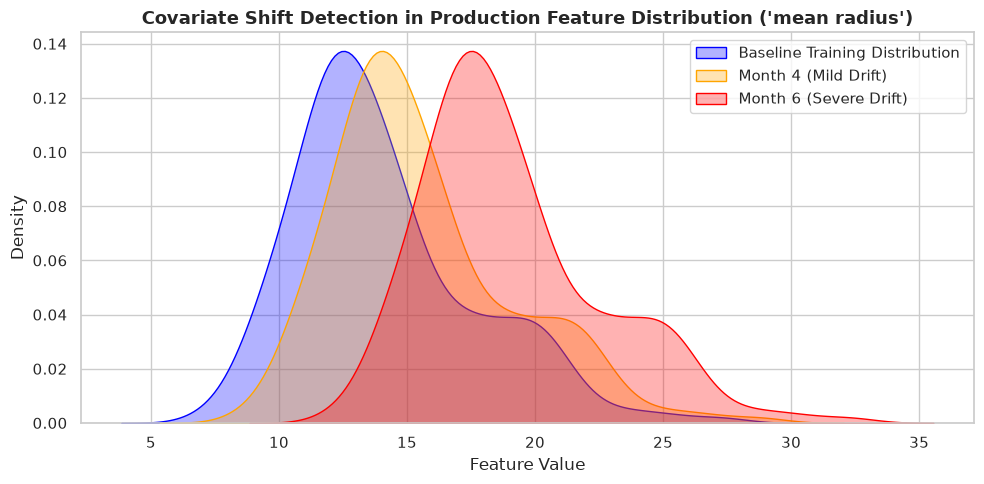

In [5]:
from scipy.stats import ks_2samp

# Recipe 4: Production Monitoring & Data Drift Detection
# Simulate incoming inference batches over 6 months
np.random.seed(2024)
baseline_feature_dist = X_train['mean radius'].values

drift_results = []
# Month 1-2: Normal distribution (no drift)
# Month 3-4: Mild covariate drift
# Month 5-6: Severe covariate drift
drift_shifts = [0.0, 0.1, 0.8, 1.5, 3.2, 5.0]

for month, shift in enumerate(drift_shifts, start=1):
    incoming_batch = baseline_feature_dist + np.random.normal(loc=shift, scale=1.0, size=len(baseline_feature_dist))
    
    # Run two-sample Kolmogorov-Smirnov test against baseline
    ks_stat, p_value = ks_2samp(baseline_feature_dist, incoming_batch)
    is_drift = p_value < 0.05
    
    drift_results.append({
        'Month': f"Month {month}",
        'Mean Shift': shift,
        'KS Statistic': ks_stat,
        'p-value': p_value,
        'Status': 'DRIFT ALERT!' if is_drift else 'Stable'
    })

df_drift = pd.DataFrame(drift_results)
print("Monthly Production Data Drift Monitoring Report:")
print(df_drift.to_string(index=False))

# Plot Drift Distribution Shift
plt.figure(figsize=(10, 5))
sns.kdeplot(baseline_feature_dist, label='Baseline Training Distribution', fill=True, color='blue', alpha=0.3)
sns.kdeplot(baseline_feature_dist + 1.5, label='Month 4 (Mild Drift)', fill=True, color='orange', alpha=0.3)
sns.kdeplot(baseline_feature_dist + 5.0, label='Month 6 (Severe Drift)', fill=True, color='red', alpha=0.3)
plt.title("Covariate Shift Detection in Production Feature Distribution ('mean radius')", fontsize=13, fontweight='bold')
plt.xlabel("Feature Value")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()

Production Serving Engine Simulation:
Sample Request Response: {'prediction': 1, 'class_label': 'Benign (1)', 'confidence': 0.9942, 'latency_ms': 13.732}
Latency Percentiles over 250 requests:
 - P50 (Median): 14.00 ms
 - P95:          15.24 ms
 - P99:          16.12 ms


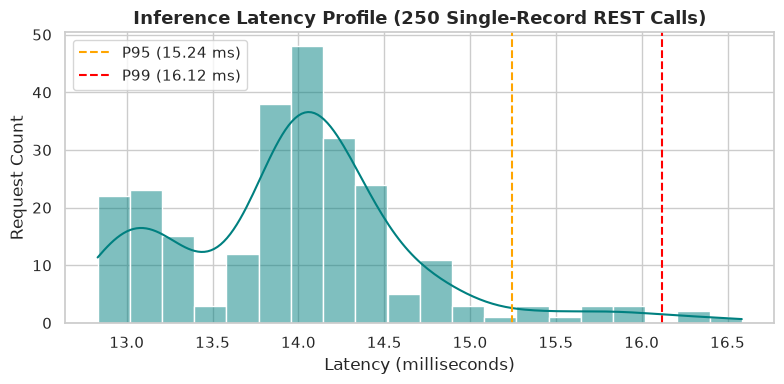

In [6]:
# Recipe 5: Production API Request Simulation & Latency Profiling
class ModelServingEngine:
    def __init__(self, model_file, meta_file):
        self.model = joblib.load(model_file)
        with open(meta_file, 'r') as f:
            self.metadata = json.load(f)
        self.expected_cols = self.metadata['input_features']
        
    def predict_request(self, payload_dict):
        start_time = time.perf_counter()
        
        # 1. Input Validation
        missing = [col for col in self.expected_cols if col not in payload_dict]
        if missing:
            return {"error": f"Missing required payload features: {missing[:3]}..."}
            
        # 2. DataFrame formatting
        df_input = pd.DataFrame([payload_dict])[self.expected_cols]
        
        # 3. Pipeline inference
        prediction = int(self.model.predict(df_input)[0])
        probabilities = self.model.predict_proba(df_input)[0].tolist()
        
        elapsed_ms = (time.perf_counter() - start_time) * 1000
        
        return {
            "prediction": prediction,
            "class_label": self.metadata['target_classes'][prediction],
            "confidence": round(max(probabilities), 4),
            "latency_ms": round(elapsed_ms, 3)
        }

serving_engine = ModelServingEngine(model_path, metadata_path)

# Simulate 250 production inference requests to measure latency percentiles
sample_record = X_test.iloc[0].to_dict()
latencies = []
for _ in range(250):
    res = serving_engine.predict_request(sample_record)
    latencies.append(res['latency_ms'])

p50 = np.percentile(latencies, 50)
p95 = np.percentile(latencies, 95)
p99 = np.percentile(latencies, 99)

print("Production Serving Engine Simulation:")
print(f"Sample Request Response: {res}")
print(f"Latency Percentiles over 250 requests:")
print(f" - P50 (Median): {p50:.2f} ms")
print(f" - P95:          {p95:.2f} ms")
print(f" - P99:          {p99:.2f} ms")

# Plot Latency Distribution
plt.figure(figsize=(8, 4))
sns.histplot(latencies, kde=True, color='teal', bins=20)
plt.axvline(p95, color='orange', linestyle='--', label=f'P95 ({p95:.2f} ms)')
plt.axvline(p99, color='red', linestyle='--', label=f'P99 ({p99:.2f} ms)')
plt.title("Inference Latency Profile (250 Single-Record REST Calls)", fontsize=13, fontweight='bold')
plt.xlabel("Latency (milliseconds)")
plt.ylabel("Request Count")
plt.legend()
plt.tight_layout()
plt.show()

In [7]:
# Practical Exercises: Deployment Governance & Automated Smoke Testing
def automated_deployment_smoke_test(model_file, meta_file, holdout_data, holdout_labels):
    print("Initiating CI/CD Production Smoke Test Suite...")
    engine = ModelServingEngine(model_file, meta_file)
    
    # Check 1: Artifact loading
    assert engine.model is not None, "FAILED: Model artifact could not be loaded."
    print(" [PASS] Artifact Integrity & Deserialization Verified.")
    
    # Check 2: Schema validation with corrupted payload
    corrupted_sample = {"mean radius": 14.5}  # missing columns
    err_res = engine.predict_request(corrupted_sample)
    assert "error" in err_res, "FAILED: Schema mismatch was not caught."
    print(" [PASS] Schema Validation Gate Confirmed.")
    
    # Check 3: Minimum accuracy SLA threshold
    preds = engine.model.predict(holdout_data)
    test_accuracy = accuracy_score(holdout_labels, preds)
    assert test_accuracy >= 0.90, f"FAILED: Model accuracy {test_accuracy:.3f} below 0.90 threshold."
    print(f" [PASS] Generalization Quality Verified: {test_accuracy:.4f} >= 0.90 threshold.")
    
    # Check 4: Latency SLA threshold
    start_t = time.perf_counter()
    _ = engine.model.predict(holdout_data[:50])
    batch_lat = (time.perf_counter() - start_t) * 1000
    assert batch_lat < 100.0, f"FAILED: Batch latency {batch_lat:.2f}ms exceeds 100ms SLA."
    print(f" [PASS] Latency SLA Compliance Verified: {batch_lat:.2f}ms < 100ms SLA.")
    
    print("\nALL PRODUCTION SMOKE TESTS PASSED! Model is certified for live traffic cutover.")

automated_deployment_smoke_test(model_path, metadata_path, X_test, y_test)

Initiating CI/CD Production Smoke Test Suite...
 [PASS] Artifact Integrity & Deserialization Verified.
 [PASS] Schema Validation Gate Confirmed.
 [PASS] Generalization Quality Verified: 0.9386 >= 0.90 threshold.
 [PASS] Latency SLA Compliance Verified: 7.08ms < 100ms SLA.

ALL PRODUCTION SMOKE TESTS PASSED! Model is certified for live traffic cutover.
